<a href="https://colab.research.google.com/github/dazzlaxx/mlops/blob/main/lab2_MLOps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Лабораторная работа №2. Эксперименты и реестр моделей**

**Вариант 5:** California Housing (scikit-learn) — регрессия: стоимость жилья

**Цель** — перевести подбор модели из разряда «помню, что с такими параметрами было лучше» в проверяемую процедуру: каждый запуск записан, запуски сравнимы между собой, выбранная модель лежит в реестре с понятным статусом.

**Что делаем:**

1. подключаем репозиторий ЛР1 к серверу MLflow, встроенному в DagsHub;
2. `train` открывает запуск и пишет параметры и модель (сигнатура, пример входа, явное окружение), `evaluate` дописывает метрики в **тот же** запуск;
3. серия из шести экспериментов — параметры меняются только в `params.yaml`, код не трогаем;
4. сравниваем запуски по метрике и закрепляем лучшие параметры коммитом;
5. реестр: версия → алиас `challenger` → сравнение с `champion` → продвижение по правилу;
6. забираем модель по алиасу: `models:/<имя>@champion`;
7. README, тег `lr2`, дополнительные задания (Optuna, autolog).

**Данные.** Продолжаем ЛР1: модель обучается на северном срезе (`Latitude >= 35.0`, версия v1, 9 348 строк). Южные районы — поток для ЛР4, поэтому здесь они не используются. Разбиение случайное (`split_by_time: false`), потому что в переписи нет даты. Главная метрика — `r2` (чем больше, тем лучше); MAE и RMSE даются в единицах 100 000 USD.


## **Шаг 1. Секреты, подключение к MLflow, клонирование**

Первая ячейка читает секреты в переменные окружения и задаёт три переменные `MLFLOW_*`. Трекинг в нашем коде включается **самим фактом наличия** `MLFLOW_TRACKING_URI`: пока она не задана, этапы работают как в ЛР1 и никуда ничего не пишут. Логин и пароль для MLflow на DagsHub — это имя пользователя и тот же токен, что и для хранилища данных.

Здесь же определены три помощника: `sh` (запуск команды с печатью вывода), `dvc` (то же для DVC через `python -m dvc`, чтобы не зависеть от `PATH`) и `commit` (добавить файлы → прогнать pre-commit → закоммитить; хук `end-of-file-fixer` иногда правит файлы, поэтому `git add` выполняется дважды).

In [1]:
import json
import os
import subprocess
import sys
import time
from pathlib import Path

from google.colab import userdata

for name in ("GITHUB_USER", "GITHUB_TOKEN", "DAGSHUB_USER", "DAGSHUB_TOKEN"):
    os.environ[name] = userdata.get(name)

REPO = "mlops"
user = os.environ["DAGSHUB_USER"]

#Трекинг включается наличием MLFLOW_TRACKING_URI (см. src/tracking.py).
os.environ["MLFLOW_TRACKING_URI"] = f"https://dagshub.com/{user}/{REPO}.mlflow"
os.environ["MLFLOW_TRACKING_USERNAME"] = user
os.environ["MLFLOW_TRACKING_PASSWORD"] = os.environ["DAGSHUB_TOKEN"]


def sh(*cmd, check=True):
    """Запускает команду и печатает вывод. Токены в аргументы не передаём."""
    proc = subprocess.run(cmd, capture_output=True, text=True)
    out = (proc.stdout + proc.stderr).strip()
    if out:
        print(out)
    if check and proc.returncode:
        raise RuntimeError(f"{' '.join(cmd[:4])} завершилась с кодом {proc.returncode}")
    return proc


def dvc(*args, check=True):
    return sh(sys.executable, "-m", "dvc", *args, check=check)


def commit(message):
    """add -> pre-commit (может поправить файлы) -> add -> commit."""
    sh("git", "add", "-A")
    sh("pre-commit", "run", "--all-files", check=False)
    sh("git", "add", "-A")
    sh("git", "commit", "-m", message, check=False)


if Path(f"/content/{REPO}").exists():
    os.chdir(f"/content/{REPO}")
print("cwd:", Path.cwd())

cwd: /content/mlops


In [2]:
repo_dir = Path(f"/content/{REPO}")
if not repo_dir.exists():
    url = (
        f"https://{os.environ['GITHUB_USER']}:{os.environ['GITHUB_TOKEN']}"
        f"@github.com/{os.environ['GITHUB_USER']}/{REPO}.git"
    )
    proc = subprocess.run(["git", "clone", "-q", url, str(repo_dir)],
                          capture_output=True, text=True)

    print(proc.stderr.replace(os.environ["GITHUB_TOKEN"], "***") or "клонировано")
os.chdir(repo_dir)
sh("git", "config", "user.email", f"{os.environ['GITHUB_USER']}@users.noreply.github.com")
sh("git", "config", "user.name", os.environ["GITHUB_USER"])
sh("git", "log", "--oneline", "-3")
sh("ls")

8027286 ЛР1: синхронизация данных с DagsHub
6d9f4f9 ЛР1: ячейка проверки воспроизводимости в ноутбуке
4a5ed9f ЛР1: доп. задания (сравнение моделей, воспроизводимость)
data
dvc.lock
dvc.yaml
models
notebooks
params.yaml
pyproject.toml
README.md
reports
src
tests
uv.lock


CompletedProcess(args=('ls',), returncode=0, stdout='data\ndvc.lock\ndvc.yaml\nmodels\nnotebooks\nparams.yaml\npyproject.toml\nREADME.md\nreports\nsrc\ntests\nuv.lock\n', stderr='')

## **Шаг 2. Окружение: добавляем MLflow в `pyproject.toml` и `uv.lock`**

MLflow — новая зависимость проекта, поэтому она попадает в `pyproject.toml`, а точные версии — в `uv.lock`. Окружение Colab разворачивается из lock-файла так же, как в ЛР1: `uv export` превращает его в список версий, `--frozen` запрещает пересчёт.

После установки обновятся `numpy` и `pandas`, поэтому **среду нужно перезапустить**. Ячейки шага 1 после перезапуска выполняются заново; шаг 2 повторять не нужно.

In [6]:
text = Path("pyproject.toml").read_text(encoding="utf-8")
if '"mlflow' not in text:
    text = text.replace(
        '    "pandera>=0.20,<0.24",\n',
        '    "pandera>=0.20,<0.24",\n    "mlflow>=3.0,<4.0",\n',
    )
    Path("pyproject.toml").write_text(text, encoding="utf-8")
assert '"mlflow' in text, "не нашёл строку с pandera в pyproject.toml"
print([line.strip() for line in text.splitlines() if "mlflow" in line])

['"mlflow>=3.0,<4.0",']


In [7]:
!pip install -q uv
!uv lock
!uv export --frozen --no-hashes -q -o /content/requirements.lock.txt
!pip install -q -r /content/requirements.lock.txt 2>&1 | tail -5

Using CPython 3.13.18 interpreter at: /usr/bin/python3
Resolved 180 packages in 2.00s
Added alembic v1.20.1
Added annotated-doc v0.0.7
Added anyio v4.16.0
Added blinker v1.9.0
Added cachetools v7.3.2
Added contourpy v1.4.0
Added cycler v0.12.1
Added databricks-sdk v0.168.0
Added docker v7.2.0
Added fastapi v0.163.2
Added flask v3.1.3
Added flask-cors v6.0.5
Added fonttools v4.68.0
Added google-auth v2.62.2
Added graphene v3.4.3
Added graphql-core v3.2.14
Added graphql-relay v3.2.0
Added gunicorn v26.2.0
Added h11 v0.16.0
Added huey v3.5.4
Added importlib-metadata v10.2.0
Added itsdangerous v2.2.0
Added jinja2 v3.1.6
Added kiwisolver v1.5.1
Added lazy-importer v0.1.0
Added mako v1.4.3
Added markupsafe v3.0.4
Added matplotlib v3.11.2
Added mlflow v3.18.0
Added mlflow-skinny v3.18.0
Added mlflow-tracing v3.18.0
Added opentelemetry-api v1.45.2
Added opentelemetry-proto v1.45.2
Added opentelemetry-sdk v1.45.2
Added opentelemetry-semantic-conventions v0.66b2
Added pillow v13.0.0
Added pretty

### Про конфликты в выводе `pip`

В конце установки строки вида `google-colab requires ..., but you have ...`. Это конфликты с пакетами, предустановленными в Colab, к лабораторной они отношения не имеют: пайплайн использует pandas, scikit-learn, DVC и MLflow.


In [3]:
import cloudpickle
import mlflow
import pandas
import sklearn

print(
    "mlflow", mlflow.__version__,
    "| scikit-learn", sklearn.__version__,
    "| pandas", pandas.__version__,
    "| cloudpickle", cloudpickle.__version__,
)

mlflow 3.18.0 | scikit-learn 1.6.1 | pandas 2.3.3 | cloudpickle 3.1.2


## **Шаг 3. Имена эксперимента и модели — в `params.yaml`**

В код имя эксперимента и модели не зашиваются: они лежат в новой секции `mlflow`. Секция `train` по-прежнему описывает модель и гиперпараметры, `evaluate.min_r2` — порог допуска. Секция `mlflow` в `dvc.yaml` не перечислена как параметр этапов, поэтому её правка не заставляет пересчитывать обучение.

In [4]:
import yaml

from src.utils import load_params

params = load_params()
params["mlflow"] = {
    "experiment": "california-housing",
    "model_name": "california-housing-regressor",
    "primary_metric": "r2",
}
Path("params.yaml").write_text(
    yaml.safe_dump(params, allow_unicode=True, sort_keys=False), encoding="utf-8"
)
print(Path("params.yaml").read_text(encoding="utf-8"))

ingest:
  source: data/external/california_housing.csv
  latitude_threshold: 35.0
  version: north
data:
  raw: data/raw/housing.csv
  target: MedHouseVal
  drop: []
  test_size: 0.2
  split_by_time: false
train:
  model: gradient_boosting
  n_estimators: 500
  max_depth: 4
  min_samples_leaf: 2
  learning_rate: 0.1
  seed: 42
evaluate:
  min_r2: 0.6
mlflow:
  experiment: california-housing
  model_name: california-housing-regressor
  primary_metric: r2



## **Шаг 4. Проверка подключения к серверу MLflow**

`set_experiment` создаёт эксперимент на сервере, если его ещё нет. Адрес сервера и ссылка на интерфейс печатаются без учётных данных.

In [5]:
import mlflow

exp_name = load_params()["mlflow"]["experiment"]
experiment = mlflow.set_experiment(exp_name)
print("сервер:     ", mlflow.get_tracking_uri())
print("эксперимент:", experiment.name, "| id:", experiment.experiment_id)
print("интерфейс:  ", f"https://dagshub.com/{user}/{REPO}/experiments")

2026/11/18 12:42:46 INFO mlflow.tracking.fluent: Experiment with name 'california-housing' does not exist. Creating a new experiment.


сервер:      https://dagshub.com/dazzlaxx/mlops.mlflow
эксперимент: california-housing | id: 0
интерфейс:   https://dagshub.com/dazzlaxx/mlops/experiments


## **Шаг 5. Модуль трекинга и этапы `train` / `evaluate`**

### Жизненный цикл запуска

Этапы пайплайна — разные процессы, поэтому запуск открывается на одном этапе и дописывается на другом:

- `train` вызывает `mlflow.start_run()`, пишет параметры, сохраняет модель и записывает идентификатор запуска в `reports/run_id.txt`;
- `evaluate` читает этот идентификатор, открывает **тот же** запуск по `run_id` и дописывает метрики.

Так в MLflow получается один запуск с полным набором сведений, а не два разрозненных. Адрес сохранённой модели пишется в `reports/model_uri.txt` — он нужен реестру.

### Две тонкости, на которых спотыкаются

- **Формат сохранения.** Современный MLflow по умолчанию пишет модели scikit-learn в формате `skops` и отказывается сохранять деревья решений, пока им явно не доверишь типы. Проще указать `serialization_format="cloudpickle"`.
- **Окружение модели.** MLflow пытается определить версии библиотек сам и заглядывает в `uv.lock`; если lock собран для другой версии Python, чем в Colab, запись модели прервётся. Поэтому окружение задаётся явным списком `pip_requirements` — это тот же принцип, что и lock-файл проекта.

Сверх лабораторного примера добавлено: `train` пишет `n_train_rows`, `n_features` и метрику `fit_seconds` (время обучения), а в тег `features` пишется порядок признаков модели.

### **5.1. `src/tracking.py`**

In [6]:
%%writefile src/tracking.py
"""Работа с MLflow. Трекинг включается только при заданном MLFLOW_TRACKING_URI.

В ЛР1 переменная не задана, и этапы работают без трекинга; начиная с ЛР2 она
указывает на сервер MLflow, встроенный в репозиторий DagsHub.
"""

from __future__ import annotations

import os
from pathlib import Path
from typing import Any

RUN_ID_FILE = Path("reports/run_id.txt")
MODEL_URI_FILE = Path("reports/model_uri.txt")


def enabled() -> bool:
    return bool(os.environ.get("MLFLOW_TRACKING_URI"))


def start_run(experiment: str, params: dict[str, Any]):
    """Открывает запуск, записывает параметры и сохраняет его идентификатор."""
    if not enabled():
        return None
    import mlflow

    mlflow.set_experiment(experiment)
    run = mlflow.start_run()
    mlflow.log_params(params)
    RUN_ID_FILE.parent.mkdir(parents=True, exist_ok=True)
    RUN_ID_FILE.write_text(run.info.run_id, encoding="utf-8")
    return run


def log_train_metrics(metrics: dict[str, float]) -> None:
    """Дописывает метрики обучения в запуск, открытый в этом же процессе."""
    if not enabled():
        return
    import mlflow

    if mlflow.active_run() is not None:
        mlflow.log_metrics(metrics)


def log_metrics(metrics: dict[str, float]) -> None:
    """Дописывает метрики в запуск, открытый на этапе train."""
    if not enabled() or not RUN_ID_FILE.exists():
        return
    import mlflow

    run_id = RUN_ID_FILE.read_text(encoding="utf-8").strip()
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metrics(metrics)


def log_model(model, features: list[str], example) -> None:
    """Сохраняет модель вместе с сигнатурой входа и запоминает её адрес.

    Адрес модели нужен реестру: в MLflow 3 он выглядит как models:/m-...,
    в MLflow 2 - как runs:/<run_id>/model. Запись в файл избавляет от
    различий между версиями сервера.
    """
    if not enabled():
        return
    import cloudpickle
    import mlflow
    import pandas
    import sklearn
    from mlflow.models import infer_signature

    mlflow.set_tag("features", ",".join(features))
    signature = infer_signature(example, model.predict(example))
    #Окружение модели задаётся явно - по тому же принципу, что и lock-файл
    #проекта: тот, кто загрузит модель, получит те же версии библиотек.
    requirements = [
        f"scikit-learn=={sklearn.__version__}",
        f"pandas=={pandas.__version__}",
        f"cloudpickle=={cloudpickle.__version__}",
    ]
    info = mlflow.sklearn.log_model(
        model,
        name="model",
        signature=signature,
        input_example=example.head(3),
        #Деревья решений MLflow по умолчанию сохраняет через skops и требует
        #явно перечислить доверенные типы; cloudpickle работает одинаково
        #на всех версиях сервера.
        serialization_format="cloudpickle",
        pip_requirements=requirements,
    )
    MODEL_URI_FILE.parent.mkdir(parents=True, exist_ok=True)
    MODEL_URI_FILE.write_text(info.model_uri, encoding="utf-8")

Writing src/tracking.py


### **5.2. `src/train.py`**

Модель обучается как и в ЛР1; новое — открытие запуска перед обучением и запись модели с сигнатурой после него. `infer_signature` берёт пример входа и предсказания модели, `input_example` сохраняет три строки примера рядом с моделью.

In [7]:
%%writefile src/train.py
"""Этап train: обучение модели на подготовленных признаках.

Если задана переменная MLFLOW_TRACKING_URI, этап дополнительно открывает запуск
в MLflow, пишет туда параметры и саму модель. Метрики допишет этап evaluate.
"""

from __future__ import annotations

import time
from pathlib import Path

import joblib
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

from src import tracking
from src.utils import ensure_parent, get_logger, load_params, set_seed

log = get_logger("train")

FEATURES = Path("data/features/train.csv")
MODEL_OUT = Path("models/model.joblib")


def make_model(tp: dict):
    name = tp["model"]
    seed = int(tp["seed"])
    if name == "random_forest":
        return RandomForestRegressor(
            n_estimators=int(tp["n_estimators"]),
            max_depth=int(tp["max_depth"]),
            min_samples_leaf=int(tp["min_samples_leaf"]),
            random_state=seed,
            n_jobs=-1,
        )
    if name == "gradient_boosting":
        return GradientBoostingRegressor(
            n_estimators=int(tp["n_estimators"]),
            max_depth=int(tp["max_depth"]),
            min_samples_leaf=int(tp["min_samples_leaf"]),
            learning_rate=float(tp["learning_rate"]),
            random_state=seed,
        )
    raise ValueError(f"неизвестная модель: {name}")


def main() -> None:
    params = load_params()
    tp = params["train"]
    target = params["data"]["target"]
    set_seed(int(tp["seed"]))

    frame = pd.read_csv(FEATURES)
    x_train = frame.drop(columns=[target])
    y_train = frame[target]

    run_params = dict(tp) | {
        "n_train_rows": len(x_train),
        "n_features": x_train.shape[1],
    }
    tracking.start_run(params["mlflow"]["experiment"], run_params)

    model = make_model(tp)
    started = time.perf_counter()
    model.fit(x_train, y_train)
    tracking.log_train_metrics({"fit_seconds": round(time.perf_counter() - started, 2)})

    bundle = {"model": model, "features": list(x_train.columns)}
    joblib.dump(bundle, ensure_parent(MODEL_OUT))
    tracking.log_model(model, list(x_train.columns), x_train.head(50))

    log.info("обучено %s на %d строках -> %s", tp["model"], len(frame), MODEL_OUT)


if __name__ == "__main__":
    main()

Overwriting src/train.py


### **5.3. `src/evaluate.py`**

Метрики пишутся в MLflow **до** проверки порога: слабый запуск, не прошедший `min_r2`, всё равно виден в сравнении.

In [8]:
%%writefile src/evaluate.py
"""Этап evaluate: метрики на тесте, запись metrics.json и данных для графика.

Если R2 ниже порога evaluate.min_r2, этап завершается с ошибкой: так модель,
которая хуже договорённого минимума, не попадает в сданную работу.
Метрики дописываются в тот же запуск MLflow, что открыл этап train.
"""

from __future__ import annotations

import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from src import tracking
from src.utils import ensure_parent, get_logger, load_params

log = get_logger("evaluate")

FEATURES = Path("data/features/test.csv")
MODEL = Path("models/model.joblib")
METRICS_OUT = Path("reports/metrics.json")
PLOT_OUT = Path("reports/plots/pred_vs_true.csv")


def main() -> None:
    params = load_params()
    target = params["data"]["target"]
    min_r2 = float(params["evaluate"]["min_r2"])

    bundle = joblib.load(MODEL)
    model, feature_names = bundle["model"], bundle["features"]

    frame = pd.read_csv(FEATURES)
    x_test = frame[feature_names]
    y_test = frame[target]
    y_pred = model.predict(x_test)

    metrics = {
        "r2": round(float(r2_score(y_test, y_pred)), 4),
        "mae": round(float(mean_absolute_error(y_test, y_pred)), 3),
        "rmse": round(float(np.sqrt(mean_squared_error(y_test, y_pred))), 3),
        "n_test": int(len(frame)),
    }
    ensure_parent(METRICS_OUT).write_text(
        json.dumps(metrics, indent=2), encoding="utf-8"
    )

    sample = pd.DataFrame({"y_true": y_test, "y_pred": y_pred}).sample(
        n=min(500, len(frame)), random_state=int(params["train"]["seed"])
    )
    sample.to_csv(ensure_parent(PLOT_OUT), index=False)

    #Метрики пишутся до проверки порога: слабый запуск тоже виден в MLflow.
    tracking.log_metrics({k: v for k, v in metrics.items() if k != "n_test"})
    log.info("метрики: %s", metrics)
    if metrics["r2"] < min_r2:
        log.error("R2 %.4f ниже порога %.2f", metrics["r2"], min_r2)
        sys.exit(1)


if __name__ == "__main__":
    main()

Overwriting src/evaluate.py


### **5.4. `dvc.yaml`**

Этапы `train` и `evaluate` теперь зависят от `src/tracking.py`: правка модуля трекинга пересчитает их, как и правка любого другого модуля.

In [9]:
%%writefile dvc.yaml
stages:
  prepare:
    cmd: python -m src.prepare
    deps:
      - src/prepare.py
      - src/schema.py
      - src/utils.py
      - data/raw/housing.csv
    params:
      - data
      - train.seed
    outs:
      - data/processed/train.csv
      - data/processed/test.csv

  featurize:
    cmd: python -m src.featurize
    deps:
      - src/featurize.py
      - src/utils.py
      - data/processed/train.csv
      - data/processed/test.csv
    params:
      - data.target
      - data.drop
    outs:
      - data/features/train.csv
      - data/features/test.csv

  train:
    cmd: python -m src.train
    deps:
      - src/train.py
      - src/tracking.py
      - src/utils.py
      - data/features/train.csv
    params:
      - train
    outs:
      - models/model.joblib

  evaluate:
    cmd: python -m src.evaluate
    deps:
      - src/evaluate.py
      - src/tracking.py
      - src/utils.py
      - models/model.joblib
      - data/features/test.csv
    params:
      - evaluate
    metrics:
      - reports/metrics.json:
          cache: false
    plots:
      - reports/plots/pred_vs_true.csv:
          x: y_true
          y: y_pred
          cache: false

Overwriting dvc.yaml


## **Шаг 6. Данные: версия v1 (север) под DVC**

В конце ЛР1 рабочая ветка осталась на версии v2 (все районы). Для ЛР2 нужна обучающая версия — **северные районы**: южные оставлены под поток ЛР4. Исходный набор лежит вне Git и DVC (`data/external/`), поэтому он выгружается заново, `ingest` режет по широте, а `dvc add` и `dvc push` кладут срез в хранилище DagsHub. Содержимое среза то же, что в v1 из ЛР1, так что в хранилище он уже лежит и загрузится мгновенно.

Ключи доступа к хранилищу в клоне не хранятся (`.dvc/config.local` не в Git), поэтому задаём их заново с флагом `--local`; вывод команд токен не печатает.

In [10]:
!python -m dvc remote modify --local origin access_key_id $DAGSHUB_TOKEN
!python -m dvc remote modify --local origin secret_access_key $DAGSHUB_TOKEN
!python -m dvc remote list

origin  s3://dvc        (default)


In [11]:
from sklearn.datasets import fetch_california_housing

Path("data/external").mkdir(parents=True, exist_ok=True)
frame = fetch_california_housing(as_frame=True).frame
frame.to_csv("data/external/california_housing.csv", index=False)
print("исходный набор:", frame.shape)

исходный набор: (20640, 9)


In [12]:
!python -m src.ingest --version north
!python -m dvc add data/raw/housing.csv
!python -m dvc push

12:46:54 ingest       версия north: 9348 строк -> data/raw/housing.csv
⠋ Checking graph


To track the changes with git, run:

	git add data/raw/housing.csv.dvc

To enable auto staging, run:

	dvc config core.autostage true


1 file pushed


## **Шаг 7. Первый прогон и проверка: один запуск — все сведения**

`dvc repro -f` выполняет все этапы заново. Флаг `-f` существенный: DVC пропускает этап, если его входы не изменились, а значит при повторе уже считавшейся конфигурации обучение не выполнится и **нового запуска в MLflow не появится**.

После прогона в MLflow должен быть ровно один запуск с параметрами, метриками и моделью, а не два разрозненных.

In [13]:
dvc("repro", "-f")

Verifying data sources in stage: 'data/raw/housing.csv.dvc'

Running stage 'prepare':
> python -m src.prepare
Updating lock file 'dvc.lock'

Running stage 'featurize':
> python -m src.featurize
Updating lock file 'dvc.lock'

Running stage 'train':
> python -m src.train
🏃 View run luxuriant-toad-69 at: https://dagshub.com/dazzlaxx/mlops.mlflow/#/experiments/0/runs/fca034f619604a3482283986f01d2803
🧪 View experiment at: https://dagshub.com/dazzlaxx/mlops.mlflow/#/experiments/0
Updating lock file 'dvc.lock'

Running stage 'evaluate':
> python -m src.evaluate
🏃 View run luxuriant-toad-69 at: https://dagshub.com/dazzlaxx/mlops.mlflow/#/experiments/0/runs/fca034f619604a3482283986f01d2803
🧪 View experiment at: https://dagshub.com/dazzlaxx/mlops.mlflow/#/experiments/0
Updating lock file 'dvc.lock'

To track the changes with git, run:

	git add dvc.lock data/raw/housing.csv.dvc

To enable auto staging, run:

	dvc config core.autostage true
Use `dvc push` to send your updates to remote storage.
1

CompletedProcess(args=('/usr/bin/python3', '-m', 'dvc', 'repro', '-f'), returncode=0, stdout="Verifying data sources in stage: 'data/raw/housing.csv.dvc'\n\nRunning stage 'prepare':\n> python -m src.prepare\nUpdating lock file 'dvc.lock'\n\nRunning stage 'featurize':\n> python -m src.featurize\nUpdating lock file 'dvc.lock'\n\nRunning stage 'train':\n> python -m src.train\n🏃 View run luxuriant-toad-69 at: https://dagshub.com/dazzlaxx/mlops.mlflow/#/experiments/0/runs/fca034f619604a3482283986f01d2803\n🧪 View experiment at: https://dagshub.com/dazzlaxx/mlops.mlflow/#/experiments/0\nUpdating lock file 'dvc.lock'\n\nRunning stage 'evaluate':\n> python -m src.evaluate\n🏃 View run luxuriant-toad-69 at: https://dagshub.com/dazzlaxx/mlops.mlflow/#/experiments/0/runs/fca034f619604a3482283986f01d2803\n🧪 View experiment at: https://dagshub.com/dazzlaxx/mlops.mlflow/#/experiments/0\nUpdating lock file 'dvc.lock'\n\nTo track the changes with git, run:\n\n\tgit add dvc.lock data/raw/housing.csv.dvc\

In [14]:
run_id = Path("reports/run_id.txt").read_text(encoding="utf-8").strip()
run = mlflow.get_run(run_id)
print("metrics.json:", Path("reports/metrics.json").read_text(encoding="utf-8"))
print("run_id:", run_id)
print("параметры:", run.data.params)
print("метрики:  ", run.data.metrics)
print("модель:   ", Path("reports/model_uri.txt").read_text(encoding="utf-8").strip())

metrics.json: {
  "r2": 0.8529,
  "mae": 0.292,
  "rmse": 0.454,
  "n_test": 1870
}
run_id: fca034f619604a3482283986f01d2803
параметры: {'model': 'gradient_boosting', 'n_estimators': '500', 'max_depth': '4', 'min_samples_leaf': '2', 'learning_rate': '0.1', 'seed': '42', 'n_train_rows': '7478', 'n_features': '9'}
метрики:   {'r2': 0.8529, 'mae': 0.292, 'rmse': 0.454, 'fit_seconds': 25.61}
модель:    models:/m-0620a73824e441c0b5e2a168047a11f1


Параметры (`params`) записаны этапом `train`, метрики (`r2`, `mae`, `rmse`) — этапом `evaluate`, и всё это в одном `run_id`. Модель лежит среди артефактов запуска вместе с сигнатурой и примером входа.

## **Шаг 8. Серия экспериментов**

Эксперимент — это прогон пайплайна с изменёнными параметрами. Меняется **только** `params.yaml`, код не трогается. Сетка: два случайных леса и четыре градиентных бустинга с разной глубиной, числом деревьев и скоростью обучения (`learning_rate` для `random_forest` не используется). Прогон серии занимает порядка 5–10 минут.


In [15]:
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
import yaml
from mlflow import MlflowClient

from src.utils import load_params

exp_name = load_params()["mlflow"]["experiment"]
client = MlflowClient()
SEED = int(load_params()["train"]["seed"])


def cfg(model, n_estimators, max_depth, min_samples_leaf, lr=0.1):
    return {
        "model": model,
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "min_samples_leaf": min_samples_leaf,
        "learning_rate": lr,
        "seed": SEED,
    }


GRID = [
    cfg("random_forest", 300, 16, 2),
    cfg("random_forest", 600, 24, 1),
    cfg("gradient_boosting", 300, 3, 2),
    cfg("gradient_boosting", 500, 4, 2),
    cfg("gradient_boosting", 800, 5, 4),
    cfg("gradient_boosting", 600, 6, 3, lr=0.05),
]


def set_train_params(variant):
    """Меняет только секцию train в params.yaml."""
    params = load_params()
    params["train"] = dict(variant)
    Path("params.yaml").write_text(
        yaml.safe_dump(params, allow_unicode=True, sort_keys=False), encoding="utf-8"
    )


def read_run_id():
    path = Path("reports/run_id.txt")
    return path.read_text(encoding="utf-8").strip() if path.exists() else None


def run_pipeline(variant):
    """Прописывает параметры и принудительно пересчитывает пайплайн."""
    set_train_params(variant)
    before = read_run_id()
    started = time.perf_counter()
    proc = subprocess.run(
        [sys.executable, "-m", "dvc", "repro", "-f"], capture_output=True, text=True
    )
    seconds = round(time.perf_counter() - started, 1)
    run_id = read_run_id()
    if run_id == before:
        print((proc.stdout + proc.stderr)[-1500:])
        raise RuntimeError("новый запуск MLflow не появился")
    return run_id, seconds, proc.returncode


def run_experiment(number, variant):
    run_id, seconds, code = run_pipeline(variant)
    path = Path("reports/metrics.json")
    if not path.exists():
        raise RuntimeError(f"этап evaluate не записал метрики (код {code})")
    metrics = json.loads(path.read_text(encoding="utf-8"))
    logged = client.get_run(run_id).data.metrics
    return {
        "№": number,
        **variant,
        "r2": metrics["r2"],
        "mae": metrics["mae"],
        "rmse": metrics["rmse"],
        "seconds": seconds,
        "fit_seconds": logged.get("fit_seconds"),
        "in_mlflow": "r2" in logged,
        "run_id": run_id,
    }


def variant_of(row):
    keys = ("model", "n_estimators", "max_depth", "min_samples_leaf")
    out = {k: row[k] for k in keys}
    out["n_estimators"] = int(out["n_estimators"])
    out["max_depth"] = int(out["max_depth"])
    out["min_samples_leaf"] = int(out["min_samples_leaf"])
    out["learning_rate"] = float(row["learning_rate"])
    out["seed"] = SEED
    return out


def describe(row):
    return (
        f"{row['model']} {int(row['n_estimators'])}/"
        f"{int(row['max_depth'])}/{int(row['min_samples_leaf'])}"
    )


def summarize(results, metric="r2"):
    """Выводы по серии: считаются из таблицы, а не придумываются."""
    ranked = results.sort_values(metric, ascending=False).reset_index(drop=True)
    best, worst = ranked.iloc[0], ranked.iloc[-1]
    spread = best[metric] - worst[metric]
    lines = [
        f"- Лучший — запуск №{best['№']} ({describe(best)}): {metric} = "
        f"{best[metric]:.4f}, MAE = {best['mae']:.3f}, RMSE = {best['rmse']:.3f}.",
        f"- Худший — запуск №{worst['№']} ({describe(worst)}): {metric} = "
        f"{worst[metric]:.4f}; разброс по серии {spread:.4f}.",
    ]
    by_model = results.groupby("model")[metric].max().sort_values(ascending=False)
    if len(by_model) > 1:
        gap = by_model.iloc[0] - by_model.iloc[-1]
        verdict = (
            "смена семейства моделей даёт заметный выигрыш"
            if gap > 0.01
            else "семейства моделей близки по качеству"
        )
        listing = ", ".join(f"{m} — {v:.4f}" for m, v in by_model.items())
        lines.append(f"- Лучшее по семействам: {listing}; разница {gap:.4f}: {verdict}.")
    same = results[results["model"] == best["model"]].copy()
    same["complexity"] = same["n_estimators"] * same["max_depth"]
    heavy = same.sort_values("complexity", ascending=False).iloc[0]
    if heavy["№"] != best["№"]:
        lines.append(
            f"- Запуск №{heavy['№']} сложнее лучшего ({describe(heavy)}), но не лучше: "
            f"{heavy[metric]:.4f} против {best[metric]:.4f}, время "
            f"{heavy['seconds']} с против {best['seconds']} с — наращивать сложность "
            "дальше смысла нет."
        )
    else:
        lines.append(
            "- Самая сложная конфигурация этого семейства оказалась лучшей: "
            "сетку стоит расширять в эту сторону."
        )
    return lines


print("серия:", len(GRID), "запусков")

серия: 6 запусков


### Запуск серии

Каждый вариант — это `params.yaml` + `dvc repro -f`. Для каждого запуска в таблицу попадают метрики из `metrics.json`, время прогона и признак того, что метрики действительно записаны в тот же запуск MLflow (`in_mlflow`).

In [16]:
rows = []
for number, variant in enumerate(GRID, start=1):
    row = run_experiment(number, variant)
    rows.append(row)
    print(
        f"№{number}: {row['model']:<18} r2={row['r2']:.4f} mae={row['mae']:.3f} "
        f"rmse={row['rmse']:.3f} ({row['seconds']} с)"
    )

results = pd.DataFrame(rows)
results.to_csv("reports/experiments.csv", index=False)
display(results.drop(columns=["run_id", "seed"]))

№1: random_forest      r2=0.8576 mae=0.283 rmse=0.447 (60.8 с)
№2: random_forest      r2=0.8585 mae=0.282 rmse=0.445 (168.1 с)
№3: gradient_boosting  r2=0.8406 mae=0.310 rmse=0.472 (35.6 с)
№4: gradient_boosting  r2=0.8529 mae=0.292 rmse=0.454 (49.2 с)
№5: gradient_boosting  r2=0.8540 mae=0.287 rmse=0.452 (73.0 с)
№6: gradient_boosting  r2=0.8616 mae=0.279 rmse=0.440 (68.7 с)


,№,model,n_estimators,max_depth,min_samples_leaf,learning_rate,r2,mae,rmse,seconds,fit_seconds,in_mlflow
0,1,random_forest,300,16,2,0.10,0.8576,0.283,0.447,60.8,28.83,True
1,2,random_forest,600,24,1,0.10,0.8585,0.282,0.445,168.1,57.94,True
2,3,gradient_boosting,300,3,2,0.10,0.8406,0.310,0.472,35.6,11.74,True
3,4,gradient_boosting,500,4,2,0.10,0.8529,0.292,0.454,49.2,25.68,True
4,5,gradient_boosting,800,5,4,0.10,0.8540,0.287,0.452,73.0,50.52,True
5,6,gradient_boosting,600,6,3,0.05,0.8616,0.279,0.440,68.7,44.68,True


### Сравнение по метрике

Сводка считается из таблицы выше. Диаграмма сохраняется в `reports/experiments_r2.png` и пойдёт в README.

- Лучший — запуск №6 (gradient_boosting 600/6/3): r2 = 0.8616, MAE = 0.279, RMSE = 0.440.
- Худший — запуск №3 (gradient_boosting 300/3/2): r2 = 0.8406; разброс по серии 0.0210.
- Лучшее по семействам: gradient_boosting — 0.8616, random_forest — 0.8585; разница 0.0031: семейства моделей близки по качеству.
- Запуск №5 сложнее лучшего (gradient_boosting 800/5/4), но не лучше: 0.8540 против 0.8616, время 73.0 с против 68.7 с — наращивать сложность дальше смысла нет.


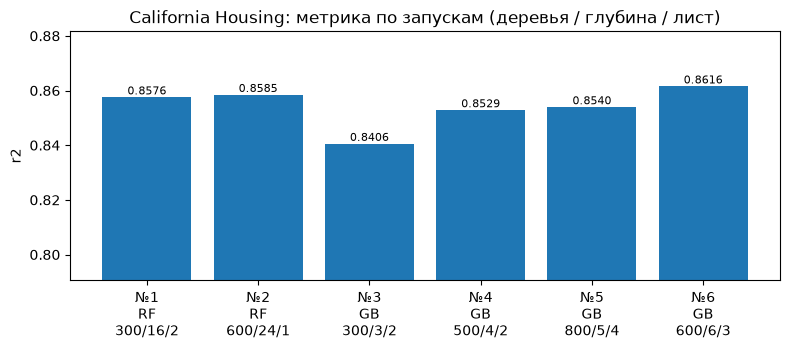

In [17]:
metric = load_params()["mlflow"]["primary_metric"]
print("\n".join(summarize(results, metric)))

labels = [
    f"№{r['№']}\n{'RF' if r['model'] == 'random_forest' else 'GB'}\n"
    f"{int(r['n_estimators'])}/{int(r['max_depth'])}/{int(r['min_samples_leaf'])}"
    for _, r in results.iterrows()
]
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(labels, results[metric])
ax.bar_label(bars, fmt="%.4f", fontsize=8)
ax.set_ylim(max(0, results[metric].min() - 0.05), results[metric].max() + 0.02)
ax.set_ylabel(metric)
ax.set_title("California Housing: метрика по запускам (деревья / глубина / лист)")
fig.tight_layout()
fig.savefig("reports/experiments_r2.png", dpi=110)
plt.show()

## **Шаг 9. Сравнение запусков в интерфейсе MLflow на DagsHub**

1. Открыла ссылку из ячейки ниже: вкладка **Experiments** репозитория.
2. Отметила галочками все запуски серии и нажмите **Compare**.
3. Сделала снимок экрана сравнения (графики) и загрузила его в следующей ячейке — он сохранится как `reports/mlflow_compare.png` и попадёт в отчёт.

Ячейка после ссылки проверяет то же самое программно: у каждого запуска серии есть и параметры, и метрики.

In [18]:
print(f"https://dagshub.com/{user}/{REPO}/experiments")

runs = mlflow.search_runs(experiment_names=[exp_name], order_by=["metrics.r2 DESC"])
cols = [
    "run_id", "params.model", "params.n_estimators", "params.max_depth",
    "params.min_samples_leaf", "params.learning_rate",
    "metrics.r2", "metrics.mae", "metrics.rmse", "metrics.fit_seconds",
]
display(runs[[c for c in cols if c in runs.columns]])
print("запусков в эксперименте:", len(runs), "| из них без метрики r2:", runs["metrics.r2"].isna().sum())

https://dagshub.com/dazzlaxx/mlops/experiments


,run_id,params.model,params.n_estimators,params.max_depth,params.min_samples_leaf,params.learning_rate,metrics.r2,metrics.mae,metrics.rmse,metrics.fit_seconds
0,3dfece42e44b4ea18c28b387d8117455,gradient_boosting,600,6,3,0.05,0.8616,0.279,0.440,44.68
1,4d7a037ce2ec45bb8e584328a7ac8750,random_forest,600,24,1,0.1,0.8585,0.282,0.445,57.94
2,bddaa2f869124bedbbcaa662c14af576,random_forest,300,16,2,0.1,0.8576,0.283,0.447,28.83
3,c5bb444f64ae4545a306bc3b2a5ef651,gradient_boosting,800,5,4,0.1,0.8540,0.287,0.452,50.52
4,fa092b127615482f8eba749f4c90fadd,gradient_boosting,500,4,2,0.1,0.8529,0.292,0.454,25.68
5,fca034f619604a3482283986f01d2803,gradient_boosting,500,4,2,0.1,0.8529,0.292,0.454,25.61
6,24474a28e1a14f0090ca7123fd590767,gradient_boosting,300,3,2,0.1,0.8406,0.310,0.472,11.74


запусков в эксперименте: 7 | из них без метрики r2: 0


In [19]:
#Загрузка снимка экрана
from google.colab import files

uploaded = files.upload()
if uploaded:
    first = next(iter(uploaded))
    Path("reports/mlflow_compare.png").write_bytes(uploaded[first])
    print("сохранено: reports/mlflow_compare.png")

Saving Сравнение с DagsHub.png to Сравнение с DagsHub.png
сохранено: reports/mlflow_compare.png


## **Шаг 10. Закрепляем лучшие параметры в `params.yaml`**

Лучший запуск выбирается по основной метрике из секции `mlflow`. Его параметры записываются в `params.yaml`, пайплайн пересчитывается (это и есть итоговый запуск, который пойдёт в реестр), результат сверяется с таблицей: детерминированный пайплайн должен дать те же метрики. Порядок фиксации тот же, что в ЛР1: `dvc push` **раньше** `git push`.

In [20]:
if "results" not in globals():
    results = pd.read_csv("reports/experiments.csv")

metric = load_params()["mlflow"]["primary_metric"]
best = results.sort_values(metric, ascending=False).iloc[0]
best_variant = variant_of(best)
print("лучший запуск:", describe(best), "| r2 в таблице:", best[metric])

run_id, seconds, code_ = run_pipeline(best_variant)
final = json.loads(Path("reports/metrics.json").read_text(encoding="utf-8"))
print("итоговые метрики:", final)
print("совпало с таблицей:", abs(final[metric] - best[metric]) < 1e-4)

лучший запуск: gradient_boosting 600/6/3 | r2 в таблице: 0.8616
итоговые метрики: {'r2': 0.8616, 'mae': 0.279, 'rmse': 0.44, 'n_test': 1870}
совпало с таблицей: True


In [21]:
dvc("push")
commit(f"ЛР2: MLflow на DagsHub, серия экспериментов, лучшие параметры ({describe(best)})")
sh("git", "push", "origin", "main")
sh("git", "log", "--oneline", "-3")

1 file pushed
[INFO] Initializing environment for https://github.com/pre-commit/pre-commit-hooks.
[INFO] Initializing environment for https://github.com/astral-sh/ruff-pre-commit.
[INFO] Installing environment for https://github.com/pre-commit/pre-commit-hooks.
[INFO] Once installed this environment will be reused.
[INFO] This may take a few minutes...
[INFO] Installing environment for https://github.com/astral-sh/ruff-pre-commit.
[INFO] Once installed this environment will be reused.
[INFO] This may take a few minutes...
check for added large files..............................................Passed
check yaml...............................................................Passed
fix end of files.........................................................Failed
- hook id: end-of-file-fixer
- exit code: 1
- files were modified by this hook

Fixing reports/model_uri.txt
Fixing reports/metrics.json
Fixing reports/run_id.txt

trim trailing whitespace............................................

CompletedProcess(args=('git', 'log', '--oneline', '-3'), returncode=0, stdout='fb3a39e ЛР2: MLflow на DagsHub, серия экспериментов, лучшие параметры (gradient_boosting 600/6/3)\n8027286 ЛР1: синхронизация данных с DagsHub\n6d9f4f9 ЛР1: ячейка проверки воспроизводимости в ноутбуке\n', stderr='')

## **Шаг 11. Реестр моделей: регистрация и алиасы**

Реестр отделяет «запуск, который что-то показал» от «модели, которую мы используем». **Версия** создаётся из конкретного запуска, а **алиас** — подвижный указатель на версию:

- `challenger` — кандидат, который ещё не сравнивали;
- `champion` — версия, которую берёт пакетное предсказание (ЛР4).

Продвижение — это правило: кандидат становится `champion`, только если его метрика **строго лучше**. Это же правило выполнится автоматически при переобучении по расписанию в ЛР4.

Модуль `src/registry.py` имеет три действия: `register` (версия из последнего запуска → `challenger`), `promote` (сравнить с `champion` и переставить алиас) и `status` (показать версии и алиасы). Если адрес вида `models:/m-…` сервер не принимает, регистрация падает обратно на `runs:/<run_id>/model`.

In [22]:
%%writefile src/registry.py
"""Реестр моделей MLflow: регистрация кандидата и продвижение в champion.

    python -m src.registry register     # версия из последнего запуска -> challenger
    python -m src.registry promote      # challenger лучше champion -> меняем алиас
    python -m src.registry status       # версии и их алиасы

Алиас champion указывает на версию, которую использует пакетное предсказание;
challenger - на кандидата, который ещё не прошёл сравнение.
"""

from __future__ import annotations

import argparse
from pathlib import Path

from src.utils import get_logger, load_params

log = get_logger("registry")

RUN_ID_FILE = Path("reports/run_id.txt")
MODEL_URI_FILE = Path("reports/model_uri.txt")


def _client():
    from mlflow import MlflowClient

    return MlflowClient()


def _metric(client, version, name: str) -> float | None:
    run = client.get_run(version.run_id)
    return run.data.metrics.get(name)


def register(model_name: str) -> str:
    import mlflow

    run_id = RUN_ID_FILE.read_text(encoding="utf-8").strip()
    candidates = [f"runs:/{run_id}/model"]
    if MODEL_URI_FILE.exists():
        candidates.insert(0, MODEL_URI_FILE.read_text(encoding="utf-8").strip())

    version, last_error = None, None
    for model_uri in candidates:
        try:
            version = mlflow.register_model(model_uri, model_name)
            break
        except Exception as exc:
            last_error = exc
            log.warning("не удалось зарегистрировать %s: %s", model_uri, exc)
    if version is None:
        raise RuntimeError("модель не зарегистрирована") from last_error

    _client().set_registered_model_alias(model_name, "challenger", version.version)
    log.info("зарегистрирована версия %s, алиас challenger", version.version)
    return version.version


def promote(model_name: str, metric: str, greater_is_better: bool = True) -> bool:
    client = _client()
    challenger = client.get_model_version_by_alias(model_name, "challenger")
    new_value = _metric(client, challenger, metric)
    if new_value is None:
        raise ValueError(f"у challenger v{challenger.version} нет метрики {metric}")

    try:
        champion = client.get_model_version_by_alias(model_name, "champion")
    except Exception:
        champion = None

    if champion is None:
        client.set_registered_model_alias(model_name, "champion", challenger.version)
        log.info(
            "champion не был задан: версия %s становится champion", challenger.version
        )
        return True

    old_value = _metric(client, champion, metric)
    if old_value is None:
        better = True
    elif greater_is_better:
        better = new_value > old_value
    else:
        better = new_value < old_value
    log.info(
        "%s: challenger v%s = %.4f, champion v%s = %s -> %s",
        metric,
        challenger.version,
        new_value,
        champion.version,
        "нет" if old_value is None else f"{old_value:.4f}",
        "продвигаем" if better else "оставляем прежнего",
    )
    if better:
        client.set_registered_model_alias(model_name, "champion", challenger.version)
    return better


def status(model_name: str, metric: str) -> list[dict]:
    """Версии модели с алиасами и значением основной метрики."""
    client = _client()
    aliases = dict(client.get_registered_model(model_name).aliases)
    versions = client.search_model_versions(f"name='{model_name}'")
    rows = []
    for version in sorted(versions, key=lambda v: int(v.version)):
        names = [a for a, v in aliases.items() if str(v) == str(version.version)]
        rows.append(
            {
                "version": int(version.version),
                "aliases": ", ".join(sorted(names)) or "-",
                metric: _metric(client, version, metric),
            }
        )
    return rows


def main() -> None:
    params = load_params()["mlflow"]
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("action", choices=["register", "promote", "status"])
    parser.add_argument("--model-name", default=params["model_name"])
    parser.add_argument("--metric", default=params["primary_metric"])
    args = parser.parse_args()

    if args.action == "register":
        register(args.model_name)
    elif args.action == "promote":
        promote(args.model_name, args.metric)
    else:
        for row in status(args.model_name, args.metric):
            log.info("%s", row)


if __name__ == "__main__":
    main()

Writing src/registry.py


In [23]:
!python -m src.registry register
!python -m src.registry promote

13:06:49 numexpr.utils NumExpr defaulting to 2 threads.
Successfully registered model 'california-housing-regressor'.
2026/11/18 13:06:53 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: california-housing-regressor, version 1
Created version '1' of model 'california-housing-regressor'.
13:06:53 registry     зарегистрирована версия 1, алиас challenger
13:06:55 numexpr.utils NumExpr defaulting to 2 threads.
13:06:58 registry     champion не был задан: версия 1 становится champion


In [25]:
from src.registry import status

model_name = load_params()["mlflow"]["model_name"]
display(pd.DataFrame(status(model_name, metric)))

,version,aliases,r2
0,1,"challenger, champion",0.8616


### Проверка правила на заведомо более слабом кандидате

Берём **худший** запуск серии, прогоняем пайплайн с его параметрами, регистрируем как новую версию (`challenger`) и запускаем сравнение. Ожидаем «оставляем прежнего»: `champion` не меняется. Потом возвращаем в `params.yaml` лучшие параметры и состояние рабочего каталога из коммита.

In [26]:
weak = results.sort_values(metric).iloc[0]
print("слабый кандидат:", describe(weak), "| r2 в таблице:", weak[metric])
run_pipeline(variant_of(weak))
print(Path("reports/metrics.json").read_text(encoding="utf-8"))

слабый кандидат: gradient_boosting 300/3/2 | r2 в таблице: 0.8406
{
  "r2": 0.8406,
  "mae": 0.31,
  "rmse": 0.472,
  "n_test": 1870
}


In [27]:
!python -m src.registry register
!python -m src.registry promote
display(pd.DataFrame(status(model_name, metric)))

13:08:38 numexpr.utils NumExpr defaulting to 2 threads.
Registered model 'california-housing-regressor' already exists. Creating a new version of this model...
2026/11/18 13:08:40 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: california-housing-regressor, version 2
Created version '2' of model 'california-housing-regressor'.
13:08:41 registry     зарегистрирована версия 2, алиас challenger
13:08:46 numexpr.utils NumExpr defaulting to 2 threads.
13:08:52 registry     r2: challenger v2 = 0.8406, champion v1 = 0.8616 -> оставляем прежнего


,version,aliases,r2
0,1,champion,0.8616
1,2,challenger,0.8406


In [28]:
#Возврат к закоммиченным лучшим параметрам: код, params.yaml, dvc.lock, отчёты — из Git,
#модель и данные этапов — из кэша DVC.
sh("git", "checkout", "--", "params.yaml", "dvc.lock", "reports")
dvc("checkout")
sh("git", "status", "--short")
print("params.yaml:", load_params()["train"])
print("metrics.json:", Path("reports/metrics.json").read_text(encoding="utf-8"))

M       models/model.joblib
?? src/registry.py
params.yaml: {'model': 'gradient_boosting', 'n_estimators': 600, 'max_depth': 6, 'min_samples_leaf': 3, 'learning_rate': 0.05, 'seed': 42}
metrics.json: {
  "r2": 0.8616,
  "mae": 0.279,
  "rmse": 0.44,
  "n_test": 1870
}



Состояние реестра после этого: `champion` остался за версией с лучшей метрикой, а слабый кандидат лежит под алиасом `challenger` как непродвинутый. Алиас не переставляется вручную «чтобы было» — иначе реестр перестаёт отражать качество.

## **Шаг 12. Модель из реестра по алиасу**

Ни пути к файлу модели, ни параметров обучения, ни номера версии: достаточно имени модели и алиаса. Именно так модель забирает пакетное предсказание в ЛР4. Заодно видно, что сигнатура входа сохранилась вместе с моделью.

In [29]:
model_uri = f"models:/{model_name}@champion"
model = mlflow.sklearn.load_model(model_uri)

target = load_params()["data"]["target"]
test = pd.read_csv("data/features/test.csv")
sample = test.drop(columns=[target]).head(5)
display(
    pd.DataFrame(
        {"y_true": test[target].head(5).round(3), "y_pred": model.predict(sample).round(3)}
    )
)

pyfunc = mlflow.pyfunc.load_model(model_uri)
print(pyfunc.metadata.signature)

,y_true,y_pred
0,3.719,2.995
1,1.531,1.820
2,2.618,2.515
3,4.750,3.630
4,1.161,1.397


inputs: 
  ['MedInc': double (required), 'HouseAge': double (required), 'AveRooms': double (required), 'AveBedrms': double (required), 'Population': double (required), 'AveOccup': double (required), 'Latitude': double (required), 'Longitude': double (required), 'rooms_per_person': double (required)]
outputs: 
  [Tensor('float64', (-1,))]
params: 
  None



## **Шаг 13. README: раздел по ЛР2**

Раздел собирается из реальных результатов серии и реестра, а не набирается руками: таблица запусков, выводы, текущие `champion` и `challenger` с номерами версий, обоснование выбора. Повторный запуск ячейки заменяет раздел, а не дублирует его.

In [30]:
reg_rows = status(model_name, metric)
by_alias = {}
for r in reg_rows:
    for alias in r["aliases"].split(", "):
        by_alias[alias] = r
champ, chall = by_alias.get("champion"), by_alias.get("challenger")


def alias_line(label, row):
    if row is None:
        return f"- {label}: не задан"
    return f"- {label}: версия **{row['version']}**, {metric} = {row[metric]:.4f}"


table = pd.DataFrame(
    {
        "№": results["№"],
        "Модель": results["model"],
        "Деревья / глубина / лист": [
            f"{int(r['n_estimators'])} / {int(r['max_depth'])} / {int(r['min_samples_leaf'])}"
            for _, r in results.iterrows()
        ],
        "learning_rate": [
            r["learning_rate"] if r["model"] == "gradient_boosting" else "-"
            for _, r in results.iterrows()
        ],
        "R²": results["r2"].map("{:.4f}".format),
        "MAE": results["mae"].map("{:.3f}".format),
        "RMSE": results["rmse"].map("{:.3f}".format),
        "Время, с": results["seconds"].round(0).astype(int),
        "run": results["run_id"].str[:8],
    }
).to_markdown(index=False)

reg_table = pd.DataFrame(reg_rows).to_markdown(index=False)

extra = ""
if (
    best["mae"] == results["mae"].min()
    and best["rmse"] == results["rmse"].min()
):
    extra = " Она же даёт наименьшие MAE и RMSE в серии."

section = [
    "## ЛР2. Эксперименты и реестр моделей",
    "",
    f"**Эксперимент в DagsHub:** https://dagshub.com/{user}/{REPO}/experiments",
    "",
    f"**Модель в реестре:** `{model_name}`",
    "",
    alias_line("champion", champ),
    alias_line("challenger", chall),
    "",
    "### Запуски",
    "",
    f"Данные: северные районы (`Latitude >= 35.0`), {int(final['n_test'])} строк в тесте; "
    "случайное разбиение 80/20, seed 42. Все запуски выполнены командой "
    "`dvc repro -f`, параметры менялись только в `params.yaml`.",
    "",
    table,
    "",
]
if Path("reports/mlflow_compare.png").exists():
    section += ["![Сравнение запусков в MLflow](reports/mlflow_compare.png)", ""]
section += [
    "![R² по запускам](reports/experiments_r2.png)",
    "",
    "### Выводы",
    "",
    *summarize(results, metric),
    "",
    "### Выбор модели",
    "",
    f"В `params.yaml` закреплена конфигурация {describe(best)} "
    f"(learning_rate {best['learning_rate']}): лучший {metric} = {best[metric]:.4f}."
    f"{extra} Она зарегистрирована как версия реестра и стала `champion`; "
    "кандидаты становятся `champion` только по правилу «метрика строго лучше».",
    "",
    "### Реестр",
    "",
    reg_table,
    "",
    "Слабый кандидат (худший запуск серии) зарегистрирован как `challenger` и "
    "`champion` не заменил — правило продвижения работает.",
    "",
    "### Как повторить",
    "",
    "    python -m dvc repro -f                 # новый запуск в MLflow",
    "    python -m src.registry register        # версия -> challenger",
    "    python -m src.registry promote         # challenger лучше champion -> алиас",
    "    python -m src.registry status          # версии и алиасы",
    "",
    "Загрузка модели без пути к файлу:",
    "",
    f"    mlflow.sklearn.load_model('models:/{model_name}@champion')",
    "",
]

readme = Path("README.md").read_text(encoding="utf-8")
marker = "## ЛР2. Эксперименты и реестр моделей"
if marker in readme:
    readme = readme[: readme.index(marker)]
readme = readme.rstrip() + "\n\n" + "\n".join(section)
Path("README.md").write_text(readme, encoding="utf-8")
print(readme[readme.index(marker):][:2500])

## ЛР2. Эксперименты и реестр моделей

**Эксперимент в DagsHub:** https://dagshub.com/dazzlaxx/mlops/experiments

**Модель в реестре:** `california-housing-regressor`

- champion: версия **1**, r2 = 0.8616
- challenger: версия **2**, r2 = 0.8406

### Запуски

Данные: северные районы (`Latitude >= 35.0`), 1870 строк в тесте; случайное разбиение 80/20, seed 42. Все запуски выполнены командой `dvc repro -f`, параметры менялись только в `params.yaml`.

|   № | Модель            | Деревья / глубина / лист   | learning_rate   |     R² |   MAE |   RMSE |   Время, с | run      |
|----:|:------------------|:---------------------------|:----------------|-------:|------:|-------:|-----------:|:---------|
|   1 | random_forest     | 300 / 16 / 2               | -               | 0.8576 | 0.283 |  0.447 |         61 | bddaa2f8 |
|   2 | random_forest     | 600 / 24 / 1               | -               | 0.8585 | 0.282 |  0.445 |        168 | 4d7a037c |
|   3 | gradient_boosting | 300 / 3 / 2        

## **Шаг 14. Проверки, коммит и тег `lr2`**

Перед отправкой: данные в хранилище (`dvc status -c`), токены в репозитории не найдены (печатаются только имена файлов, но не значения), `.dvc/config.local` игнорируется Git. Затем коммит, `dvc push` и `git push`, тег `lr2`.

In [31]:
dvc("status", "-c")
for secret in ("GITHUB_TOKEN", "DAGSHUB_TOKEN"):
    hits = subprocess.run(
        ["git", "grep", "-l", "-F", "-e", os.environ[secret]],
        capture_output=True, text=True,
    ).stdout.split()
    print(secret, "->", ", ".join(hits) if hits else "в репозитории не найден")
sh("git", "check-ignore", "-v", ".dvc/config.local")

Cache and remote 'origin' are in sync.
GITHUB_TOKEN -> в репозитории не найден
DAGSHUB_TOKEN -> notebooks/lr1_data_and_pipeline.ipynb
.gitignore:3:.dvc/config.local	.dvc/config.local


CompletedProcess(args=('git', 'check-ignore', '-v', '.dvc/config.local'), returncode=0, stdout='.gitignore:3:.dvc/config.local\t.dvc/config.local\n', stderr='')

In [32]:
dvc("push")
commit("ЛР2: README — эксперименты, реестр, champion/challenger")
sh("git", "push", "origin", "main")
sh("git", "tag", "-f", "lr2")
sh("git", "push", "origin", "lr2", "--force")
sh("git", "log", "--oneline", "-3")
sh("git", "tag", "-l")

Everything is up to date.
check for added large files..............................................Passed
check yaml...............................................................Passed
fix end of files.........................................................Passed
trim trailing whitespace.................................................Passed
detect private key.......................................................Passed
ruff check...............................................................Passed
ruff format..............................................................Passed
[main e7f4cc4] ЛР2: README — эксперименты, реестр, champion/challenger
 2 files changed, 192 insertions(+)
 create mode 100644 src/registry.py
To https://github.com/dazzlaxx/mlops.git
   fb3a39e..e7f4cc4  main -> main
To https://github.com/dazzlaxx/mlops.git
 * [new tag]         lr2 -> lr2
e7f4cc4 ЛР2: README — эксперименты, реестр, champion/challenger
fb3a39e ЛР2: MLflow на DagsHub, серия экспериментов, лучшие

CompletedProcess(args=('git', 'tag', '-l'), returncode=0, stdout='data-v1\ndata-v2\nlr1\nlr2\n', stderr='')

### Сохранение ноутбука в репозиторий

Токены в ноутбуке не хранятся, а выводы ячеек их не содержат.